In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
zif_ref = zipfile.ZipFile("drive/MyDrive/Data/lumpy_skin.zip")
zif_ref.extractall()
zif_ref.close()

In [ ]:
import os

# Get the directory where the files were extracted
extracted_dir = "lumpy_skin"  # Assuming the zip file's contents are extracted into a directory with the same name

# Count the number of files and/or directories within the extracted directory
total_files = 0
for base, _, files in os.walk(extracted_dir):
    for Files in files:
        total_files += 1

print(f"Total number of data items (files) in the dataset: {total_files}")

Total number of data items (files) in the dataset: 1356


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import ResNet152
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization, Input
from tensorflow.keras.models import Model

# Import helper functions
def split_dir_to_train_test_val(directory = "lumpy_skin/",
                            train_size = 0.7,
                            test_size = 0.2,
                            val_size = 0.1):
  """
  Creates 3 folders for Train, Test and Validation data
  """
  import os
  import random
  import shutil

  # Set random seed
  rng = random.Random(42)

  for root, folders, files in os.walk(directory):
    for folder in folders:
      # Create list of the files
      list_of_files = []
      for file_name in os.listdir(root+folder+"/"):
        list_of_files.append(file_name)

      #  Shuffle the list
      rng.shuffle(list_of_files)

      # Create lists of files
      train_files = list_of_files[:int(len(list_of_files)*train_size)]
      test_files = list_of_files[int(len(list_of_files)*train_size) : int(len(list_of_files)*(train_size+test_size))]
      val_files = list_of_files[int(len(list_of_files)*(train_size+test_size)):]

      # Create folders and files for train data
      for one_file in train_files:

        # Copy  files
        dest_dir = "files/train/"+folder+"/"
        os.makedirs(dest_dir, exist_ok=True)

        shutil.copy2(src=(root+folder+"/"+one_file),
                    dst=(dest_dir+one_file))
      print(f"Folder {folder}. Train data copied. {len(train_files)} files")

      # Create folders and files for test data
      for one_file in test_files:
        # Copy  files
        dest_dir = "files/test/"+folder+"/"
        os.makedirs(dest_dir, exist_ok=True)

        shutil.copy2(src=(root+folder+"/"+one_file),
                    dst=(dest_dir+one_file))
      print(f"Folder {folder}. Test data copied. {len(test_files)} files")

      # Create folders and files for validation data
      for one_file in val_files:

        # Copy  files
        dest_dir = "files/validation/"+folder+"/"
        os.makedirs(dest_dir, exist_ok=True)

        shutil.copy2(src=(root+folder+"/"+one_file),
                    dst=(dest_dir+one_file))
      print(f"Folder {folder}. Validation data copied. {len(val_files)} files")




def get_class_names_from_folder(directory):
  """
  Get the classnames from train folder for example
  """
  import pathlib
  import numpy as np
  data_dir = pathlib.Path(directory)
  class_names = np.array(sorted([item.name for item in data_dir.glob("*")])) # Created a list of class names
  return class_names
  print(class_names)

In [ ]:
split_dir_to_train_test_val(directory="lumpy_skin/",
                            train_size=0.7,
                            test_size=0.2,
                            val_size=0.1)

Folder Lumpy Skin. Train data copied. 471 files
Folder Lumpy Skin. Test data copied. 135 files
Folder Lumpy Skin. Validation data copied. 68 files
Folder Normal Skin. Train data copied. 477 files
Folder Normal Skin. Test data copied. 136 files
Folder Normal Skin. Validation data copied. 69 files


In [ ]:
class_names = get_class_names_from_folder(directory="files/train/")
class_names

array(['Lumpy Skin', 'Normal Skin'], dtype='<U11')

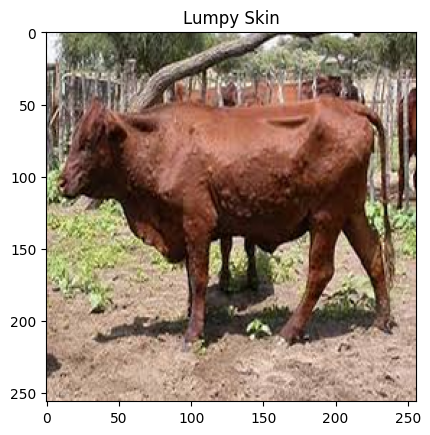

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import os
import random

def visualize_random_image(target_dir, target_class):
  """
  Visualises random image from exact directory
  """
  image_dir = target_dir + target_class
  random_image = random.sample(os.listdir(image_dir), 1)

  img = mpimg.imread(image_dir + "/" + random_image[0])
  plt.imshow(img)
  plt.title(target_class)

visualize_random_image("files/test/", "Lumpy Skin")

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1/255.,
                                  rotation_range=30,
                                  width_shift_range=0.3,
                                  height_shift_range=0.3,
                                  zoom_range=0.3,
                                  shear_range=0.3,
                                  horizontal_flip=True,
                                  vertical_flip=True,
                                  brightness_range=[0.6, 1.4],
                                  channel_shift_range=30.0)
test_datagen = ImageDataGenerator(rescale=1/255.,
                                  rotation_range=30,
                                  width_shift_range=0.3,
                                  height_shift_range=0.3,
                                  zoom_range=0.3,
                                  shear_range=0.3,
                                  horizontal_flip=True,
                                  vertical_flip=True,
                                  brightness_range=[0.6, 1.4],
                                  channel_shift_range=30.0)
val_datagen = ImageDataGenerator(rescale=1/255.,
                                  rotation_range=30,
                                  width_shift_range=0.3,
                                  height_shift_range=0.3,
                                  zoom_range=0.3,
                                  shear_range=0.3,
                                  horizontal_flip=True,
                                  vertical_flip=True,
                                  brightness_range=[0.6, 1.4],
                                  channel_shift_range=30.0)

train_data = train_datagen.flow_from_directory(directory="files/train",
                                               target_size=(224, 224),
                                               batch_size=32,
                                               class_mode="categorical")

test_data = test_datagen.flow_from_directory(directory="files/test",
                                               target_size=(224, 224),
                                               batch_size=32,
                                               class_mode="categorical")

validation_data = val_datagen.flow_from_directory(directory="files/validation",
                                               target_size=(224, 224),
                                               batch_size=32,
                                               class_mode="categorical")

Found 948 images belonging to 2 classes.
Found 271 images belonging to 2 classes.
Found 137 images belonging to 2 classes.


In [ ]:

import cv2
import numpy as np

def apply_threshold(image):
    # Convert image to grayscale if not already
    if len(image.shape) == 3 and image.shape[2] == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    # Apply binary thresholding
    _, thresholded_image = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY)
    return thresholded_image

# Example usage in preprocessing pipeline
def preprocess_images(images):
    processed_images = []
    for img in images:
        # Apply thresholding
        img = apply_threshold(img)
        # Normalize to [0, 1]
        img = img / 255.0
        processed_images.append(img)
    return np.array(processed_images)


In [ ]:
# Custom preprocessing function for applying threshold
def preprocess_images_with_threshold(generator, directory, target_size, batch_size, class_mode):
    for batch in generator.flow_from_directory(
        directory=directory,
        target_size=target_size,
        batch_size=batch_size,
        class_mode=class_mode
    ):
        images, labels = batch
        processed_images = preprocess_images(images)  # Apply thresholding
        # Add a channel dimension if needed
        if len(processed_images.shape) == 3:  # If grayscale, add channel dim
            processed_images = np.expand_dims(processed_images, axis=-1)
        yield processed_images, labels

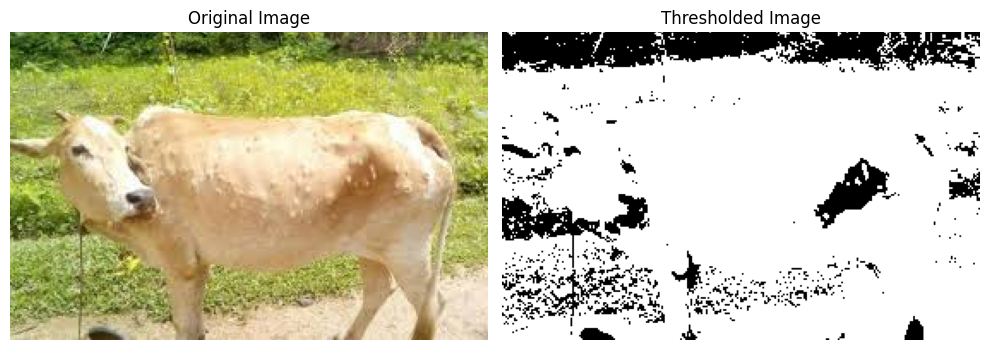

In [ ]:
# Fungsi untuk menampilkan gambar asli dan threshold
def display_random_image_with_threshold(target_dir, target_class):
    """
    Menampilkan gambar asli dan threshold dari direktori target secara acak.
    """
    # Path direktori target
    image_dir = os.path.join(target_dir, target_class)

    # Pilih gambar secara acak
    random_image = random.sample(os.listdir(image_dir), 1)[0]  # Ambil satu gambar secara acak
    random_image_path = os.path.join(image_dir, random_image)

    # Load original image
    original_image = cv2.imread(random_image_path)  # Load image in BGR format
    original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)  # Convert to RGB

    # Apply threshold
    thresholded_image = apply_threshold(original_image)

    # Plot the images
    plt.figure(figsize=(10, 5))

    # Plot original image
    plt.subplot(1, 2, 1)
    plt.imshow(original_image)
    plt.title("Original Image")
    plt.axis("off")

    # Plot thresholded image
    plt.subplot(1, 2, 2)
    plt.imshow(thresholded_image, cmap="gray")  # Thresholded image is grayscale
    plt.title("Thresholded Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Contoh penggunaan
display_random_image_with_threshold(target_dir="files/test/", target_class="Lumpy Skin")

In [ ]:
# Adjust generators to include preprocessing
train_data_gen = preprocess_images_with_threshold(train_datagen, "files/train", (224, 224), 32, "categorical")
test_data_gen = preprocess_images_with_threshold(test_datagen, "files/test", (224, 224), 32, "categorical")
val_data_gen = preprocess_images_with_threshold(val_datagen, "files/validation", (224, 224), 32, "categorical")


In [ ]:
from tensorflow.keras.layers import Dense, Activation,Dropout,Conv2D, MaxPooling2D,BatchNormalization, Flatten,Input

base_model=tf.keras.applications.InceptionV3(include_top=False, weights="imagenet",input_tensor=Input(shape=(224,224,3)))

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
base_model.summary()

Model: "inception_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 224, 224, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 111, 111, 32)   │            864 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 111, 111, 32)   │             96 │ conv2d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation (Activation)   │ (None, 111, 111, 32)   │              0 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 109, 109, 32)   │          9,216 │ activation[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 109, 109, 32)   │             96 │ conv2d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_1 (Activation) │ (None, 109, 109, 32)   │              0 │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 109, 109, 64)   │         18,432 │ activation_1[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 109, 109, 64)   │            192 │ conv2d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_2 (Activation) │ (None, 109, 109, 64)   │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 54, 54, 64)     │              0 │ activation_2[0][0]     │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 54, 54, 80)     │          5,120 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 54, 54, 80)     │            240 │ conv2d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_3 (Activation) │ (None, 54, 54, 80)     │              0 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 52, 52, 192)    │        138,240 │ activation_3[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4     │ (None, 52, 52, 192)    │            576 │ conv2d_4[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_4 (Activat

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 21,768,352 (83.04 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-30]:  # Membekukan layer awal
    layer.trainable = False

In [ ]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import GlobalAveragePooling2D, BatchNormalization, Dense, Dropout
from tensorflow.keras.models import Model

# Tambahkan lapisan kustom di atas model dasar
x = base_model.output
x = GlobalAveragePooling2D()(x)  # GlobalAveragePooling2D sebagai pengganti Flatten
x = BatchNormalization()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
x = BatchNormalization()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(2, activation='softmax')(x)  # Lapisan output dengan softmax

# Buat model kustom
model = Model(inputs=base_model.input, outputs=output)

In [ ]:
# Optimizer dan Learning Rate Scheduler
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-4,
    decay_steps=1000,
    decay_rate=0.9,
    staircase=True
)

optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)

In [ ]:
# Compile Model
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 224, 224, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 111, 111, 32)   │            864 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 111, 111, 32)   │             96 │ conv2d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation (Activation)   │ (None, 111, 111, 32)   │              0 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 109, 109, 32)   │          9,216 │ activation[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 109, 109, 32)   │             96 │ conv2d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_1 (Activation) │ (None, 109, 109, 32)   │              0 │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 109, 109, 64)   │         18,432 │ activation_1[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 109, 109, 64)   │            192 │ conv2d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_2 (Activation) │ (None, 109, 109, 64)   │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 54, 54, 64)     │              0 │ activation_2[0][0]     │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 54, 54, 80)     │          5,120 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 54, 54, 80)     │            240 │ conv2d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_3 (Activation) │ (None, 54, 54, 80)     │              0 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 52, 52, 192)    │        138,240 │ activation_3[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4     │ (None, 52, 52, 192)    │            576 │ conv2d_4[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_4 (Activat

 Total params: 22,369,698 (85.33 MB)

 Trainable params: 5,718,338 (21.81 MB)

 Non-trainable params: 16,651,360 (63.52 MB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_data.classes),
    y=train_data.classes
)
class_weights = dict(enumerate(class_weights))

In [ ]:
history = model.fit(train_data,
                    batch_size=32,
                    epochs=100,
                    validation_data=validation_data,
                    class_weight=class_weights,

                    )

Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


30/30 ━━━━━━━━━━━━━━━━━━━━ 180s 5s/step - accuracy: 0.5738 - loss: 0.8623 - val_accuracy: 0.7372 - val_loss: 0.5253
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 194s 5s/step - accuracy: 0.7078 - loss: 0.6814 - val_accuracy: 0.8029 - val_loss: 0.4033
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 201s 5s/step - accuracy: 0.7472 - loss: 0.5886 - val_accuracy: 0.8102 - val_loss: 0.4035
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 157s 5s/step - accuracy: 0.7778 - loss: 0.4885 - val_accuracy: 0.8175 - val_loss: 0.4032
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 201s 5s/step - accuracy: 0.7427 - loss: 0.5418 - val_accuracy: 0.8321 - val_loss: 0.3754
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 159s 5s/step - accuracy: 0.7703 - loss: 0.5153 - val_accuracy: 0.8686 - val_loss: 0.3428
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 205s 5s/step - accuracy: 0.8091 - loss: 0.4577 - val_accuracy: 0.8467 - val_loss: 0.3378
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 206s 5s/step - accuracy: 0.7896 - loss: 0.4439 - val_accuracy: 0.8321 - val_l

In [ ]:
model.evaluate(test_data)

9/9 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.8703 - loss: 0.5242


[0.5815657377243042, 0.8413284420967102]

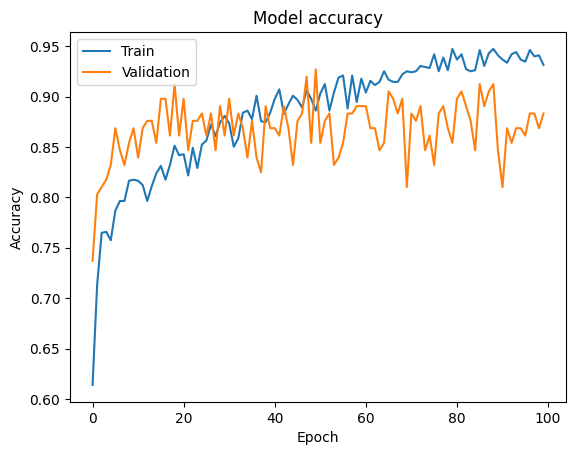

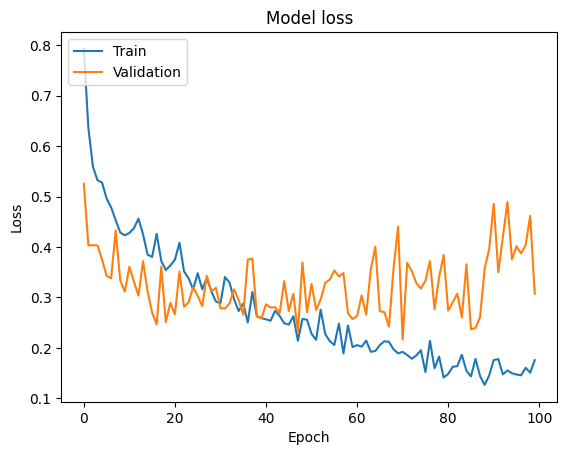

In [ ]:
# prompt: buatkan plot dari hasil training model di atas

import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
y_pred = model.predict(test_data)

9/9 ━━━━━━━━━━━━━━━━━━━━ 46s 5s/step


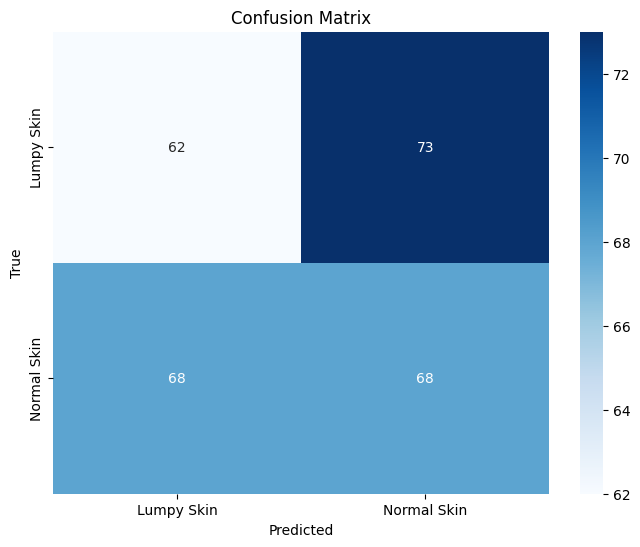

In [ ]:
# prompt: buatkan confusion matrixs nya dari model diatas

import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming y_pred contains predicted probabilities
y_pred_classes = np.argmax(y_pred, axis=1)

# Get true labels from test_data
y_true = test_data.classes

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()